# Project 1: Wealth Inequality in Denmark
Starter notebook. Add your names, code and interpretations. Keep your simulation module (.py) beside this notebook.

**Group name:**  
**Members:**

The tasks are in the project PDF. [Course plan: deadline and rules](https://github.com/NumEconCopenhagen/ProgEcon-lectures/blob/main/PLAN_autumn26.md#projects-and-exam) · [Hand-in: Dropbox file request](https://www.dropbox.com/request/6cn75p9izf51x3am6kfe) (one `GroupName_P1_v1.zip` per group)

## Download function
`download('FORMUE16', PERCENTIL='*', ...)` asks Statistics Denmark for table FORMUE16. Each keyword is one **variable code** and its value selects the rows you want; `'*'` selects all values. This is the same information as the `variables` list in the Lecture 10 API notebook, written more compactly, and it needs no extra package. The result is a DataFrame with one column per variable and the number in `value`.

To find the codes of another table, open its table information in your browser, for example [FORMUE15](https://api.statbank.dk/v1/tableinfo/FORMUE15?lang=en&format=JSON).

In [1]:
from io import BytesIO
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(table, **selectors):
    """Download a StatBank table as a DataFrame. Each keyword is one variable code; '*' selects all values."""
    url = f'https://api.statbank.dk/v1/data/{table}/CSV'
    params = dict(lang='en', valuePresentation='Code', **selectors)
    response = requests.get(url, params=params, timeout=45)
    response.raise_for_status()
    frame = pd.read_csv(BytesIO(response.content), sep=';', dtype=str, encoding='utf-8-sig')
    frame = frame.rename(columns={frame.columns[-1]: 'value'})
    frame['value'] = pd.to_numeric(frame['value'].str.replace(',', '.', regex=False))
    return frame

settings = dict(PRISENHED='006', ALDER='*', Tid='2024')  # nominal DKK, all age groups, 2024
percentiles = download('FORMUE16', PERCENTIL='*', **settings)
percentiles.head()

,PERCENTIL,PRISENHED,ALDER,TID,value
0,P1,006,1802,2024,-872193
1,P1,006,1829,2024,-474253
2,P1,006,3039,2024,-1184850
3,P1,006,4049,2024,-1212373
4,P1,006,5059,2024,-1007915


## 1.1   Download and Read the Tables
Tasks and hints: PDF Section 1.1.

In [6]:
settings = dict(PRISENHED='006', ALDER='*', Tid='2024')

percentiles = download('FORMUE16', PERCENTIL='*', **settings)
percentiles.head()

,PERCENTIL,PRISENHED,ALDER,TID,value
0,P1,006,1802,2024,-872193
1,P1,006,1829,2024,-474253
2,P1,006,3039,2024,-1184850
3,P1,006,4049,2024,-1212373
4,P1,006,5059,2024,-1007915


## 1.2   Plot the Age Profiles
Tasks and hints: PDF Section 1.2.

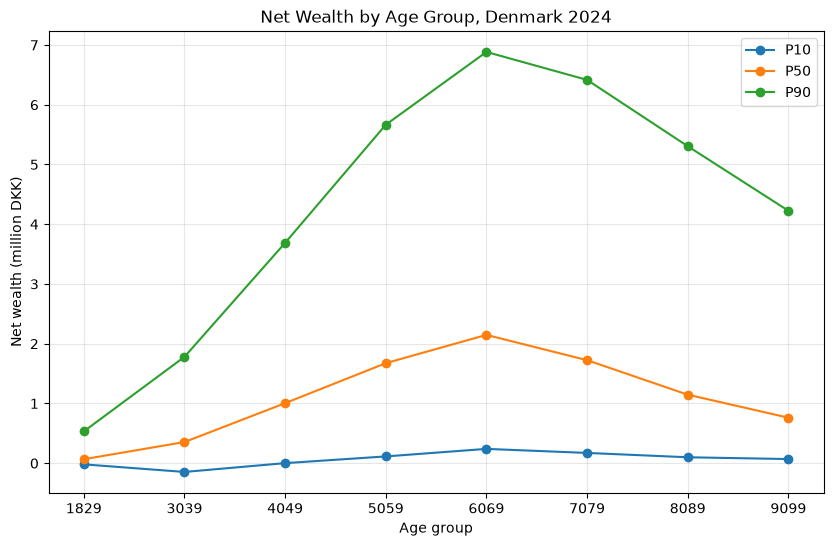

PERCENTIL        10         50         90  upper_gap  lower_gap
ALDER                                                          
1829       -19750.0    66507.0   532429.0   465922.0    86257.0
3039      -146586.0   353896.0  1780078.0  1426182.0   500482.0
4049          912.0  1004750.0  3688269.0  2683519.0  1003838.0
5059       113324.0  1674287.0  5665305.0  3991018.0  1560963.0
6069       239280.0  2147564.0  6883537.0  4735973.0  1908284.0
7079       171695.0  1724056.0  6415595.0  4691539.0  1552361.0
8089        99096.0  1146853.0  5305568.0  4158715.0  1047757.0
9099        69252.0   761637.0  4225415.0  3463778.0   692385.0

Widest upper gap: 6069
Amount: 4,735,973 DKK

Age groups with negative P10: ['1829', '3039']


In [3]:

# 1.2 Plot the Age Profiles

# Keep the eight age groups (exclude all adults)
age_order = ['1829', '3039', '4049', '5059',
             '6069', '7079', '8089', '9099']

df = percentiles[percentiles['ALDER'].isin(age_order)].copy()

# Convert percentile codes (P10 -> 10)
df['PERCENTIL'] = df['PERCENTIL'].str.replace('P', '').astype(int)

# One row per age group, one column per percentile
age_profiles = df.pivot_table(
    index='ALDER',
    columns='PERCENTIL',
    values='value'
).reindex(age_order)

# Plot P10, P50 and P90
plt.figure(figsize=(10, 6))

for p in [10, 50, 90]:
    plt.plot(age_profiles.index, age_profiles[p] / 1e6,
             marker='o', label=f'P{p}')

plt.xlabel('Age group')
plt.ylabel('Net wealth (million DKK)')
plt.title('Net Wealth by Age Group, Denmark 2024')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Calculate upper and lower gaps
age_profiles['upper_gap'] = age_profiles[90] - age_profiles[50]
age_profiles['lower_gap'] = age_profiles[50] - age_profiles[10]

print(age_profiles[[10, 50, 90, 'upper_gap', 'lower_gap']])

# Largest upper gap
widest_age = age_profiles['upper_gap'].idxmax()
widest_gap = age_profiles['upper_gap'].max()

print(f'\nWidest upper gap: {widest_age}')
print(f'Amount: {widest_gap:,.0f} DKK')

# Age groups with negative P10
negative_p10 = age_profiles.index[age_profiles[10] < 0].tolist()
print(f'\nAge groups with negative P10: {negative_p10}')


**Interpretation.** Write your answer here.

## 1.3   Who Has Negative Net Wealth?
Tasks and hints: PDF Section 1.3.

**Interpretation.** Write your answer here.

## 2.1   Give Everybody Their Age-Group Median
Tasks and hints: PDF Section 2.1.

In [ ]:
# Write your simulation function in a .py file next to this notebook and import it here.

**Interpretation.** Write your answer here.

## 2.2   Allow Wealth to Vary Within Each Age Group
Tasks and hints: PDF Section 2.2.

## 2.3   Compare Both Economies with Denmark
Tasks and hints: PDF Section 2.3.

**Interpretation.** Write your answer here.

## 2.4   An Older Denmark
Tasks and hints: PDF Section 2.4.

**Interpretation.** Write your answer here.

Data: [StatBank FORMUE16](https://www.statbank.dk/FORMUE16) and [StatBank FORMUE15](https://www.statbank.dk/FORMUE15).